# Lab 7: Go-to-goal, three controllers

The robot drives the digit **32** as 12 waypoints. It estimates its pose with odometry (Lab 6) and drives to each waypoint with a go-to-goal controller. The three versions differ only in how the forward power `v` is chosen (formulas in the README). Each version ran in the TRIK Studio simulator and on the real robot with the same gains.

Logs: one `x,y,time` line per sample (cm, cm, ms since start), no header.

In [1]:
from google.colab import files      # file work module
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization

uploaded = files.upload()           # select all six txt files

# Planned waypoints: start point + the 12 waypoints of the TRIK program
wp = np.array([[0, 0], [30, 0], [30, 30], [0, 30], [30, 30], [30, 60], [0, 60],
               [50, 60], [80, 60], [80, 30], [50, 30], [50, 0], [80, 0]])

versions = {'v1': 'V1: P controller', 'v2': 'V2: turn, then drive', 'v3': 'V3: cos controller'}
sim  = {v: np.loadtxt(f'odometry_data_sim_32_{v}.txt',  delimiter=',', unpack=True) for v in versions}
real = {v: np.loadtxt(f'odometry_data_real_32_{v}.txt', delimiter=',', unpack=True) for v in versions}

Saving odometry_data_real_32_v1.txt to odometry_data_real_32_v1.txt
Saving odometry_data_real_32_v2.txt to odometry_data_real_32_v2.txt
Saving odometry_data_real_32_v3.txt to odometry_data_real_32_v3.txt
Saving odometry_data_sim_32_v1.txt to odometry_data_sim_32_v1.txt
Saving odometry_data_sim_32_v2.txt to odometry_data_sim_32_v2.txt
Saving odometry_data_sim_32_v3.txt to odometry_data_sim_32_v3.txt


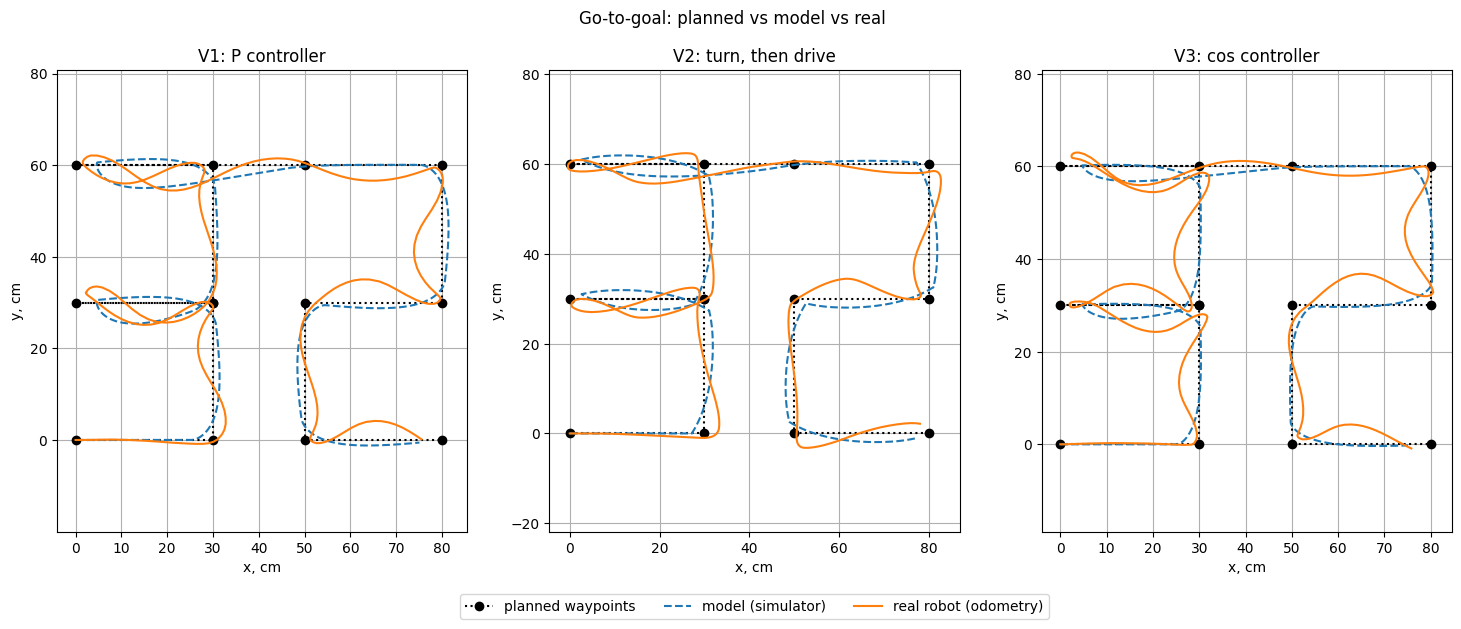

In [2]:
# 1. Planned path vs simulated vs real
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
for ax, (v, name) in zip(axs, versions.items()):
    x_s, y_s, t_s = sim[v]
    x_r, y_r, t_r = real[v]
    ax.plot(wp[:, 0], wp[:, 1], 'k:o', label='planned waypoints')
    ax.plot(x_s, y_s, '--', label='model (simulator)')
    ax.plot(x_r, y_r,       label='real robot (odometry)')
    ax.axis('equal'); ax.grid(True)
    ax.set_xlabel('x, cm'); ax.set_ylabel('y, cm'); ax.set_title(name)
axs[0].legend(loc='upper center', bbox_to_anchor=(1.7, -0.12), ncol=3)
fig.suptitle('Go-to-goal: planned vs model vs real')
plt.show()

**What the plot shows.** All three versions draw the 32 in both runs. In the simulator, V1 swings widest at the two 180° reversals on the left, and V3 has the squarest corners. On the real robot, V1 and V3 weave across the straight lines, while V2 stays much closer to them.

In [3]:
# 2. How close did each run get to each waypoint?
def waypoint_miss(x, y, wp):
    return np.array([np.min(np.hypot(x - px, y - py)) for px, py in wp])

miss = {f'{v} {k}': waypoint_miss(d[v][0], d[v][1], wp) for v in versions for k, d in [('sim', sim), ('real', real)]}
print('waypoint ' + ''.join(f'{c:>9}' for c in miss))
for i, (px, py) in enumerate(wp):
    print(f'{i:2d} ({px:2d},{py:2d})' + ''.join(f'{m[i]:9.1f}' for m in miss.values()))
print('mean 1-12' + ''.join(f'{m[1:].mean():9.1f}' for m in miss.values()))

waypoint    v1 sim  v1 real   v2 sim  v2 real   v3 sim  v3 real
 0 ( 0, 0)      0.0      0.0      0.0      0.0      0.0      0.0
 1 (30, 0)      2.3      0.4      2.4      1.0      3.1      1.1
 2 (30,30)      1.6      0.5      1.6      0.4      2.4      1.6
 3 ( 0,30)      4.6      3.0      2.8      1.0      4.8      2.0
 4 (30,30)      1.6      0.5      1.6      0.4      2.4      1.6
 5 (30,60)      2.2      2.1      1.8      1.4      2.2      0.9
 6 ( 0,60)      4.6      1.6      2.8      0.2      4.8      3.2
 7 (50,60)      0.3      0.5      0.2      0.9      0.2      0.5
 8 (80,60)      2.3      1.3      2.2      1.7      3.0      0.8
 9 (80,30)      2.1      0.7      1.7      1.9      3.0      2.1
10 (50,30)      2.6      2.0      2.8      0.4      3.2      2.2
11 (50, 0)      2.1      1.3      1.7      0.8      2.9      2.1
12 (80, 0)      5.0      4.5      2.9      2.9      4.9      4.3
mean 1-12      2.6      1.5      2.0      1.1      3.1      1.9


**What the table shows.** Every miss is within the acceptance radius ε (5 cm for V1 and V3, 3 cm for V2), because the robot switches to the next waypoint as soon as it is within ε. In the simulator, the largest misses are at the points the robot drives straight at: (0,30), (0,60) and (80,0). On the real robot, (80,0) is the largest miss in every version, because the program stops as soon as it is within ε of the last point. The real misses are smaller than the simulated ones because the real robot moves further between two loop passes (about 60 ms, at higher speed) and keeps rolling for a moment after the switch.

The miss distances come from the robot's own odometry, so they show how well the **controller** worked, not where the robot **actually** went.

In [4]:
# 3. Run time
for v, name in versions.items():
    t_s, t_r = sim[v][2], real[v][2]
    print(f'{name}: sim {(t_s[-1]-t_s[0])/1000:.1f} s | real {(t_r[-1]-t_r[0])/1000:.1f} s')

V1: P controller: sim 35.8 s | real 16.3 s
V2: turn, then drive: sim 41.9 s | real 19.4 s
V3: cos controller: sim 36.7 s | real 18.5 s


**Run time.** The real robot finishes in about half the simulator time at the same power, because its wheels are bigger (r = 4.3 cm vs 2.8 cm) and its motors turn faster. V2 is the slowest in both runs because it stops to turn on the spot.